# Lab 10 - P1: Búsqueda por Rango
n = elementos de la colección, D = dimensiones (16).

### Carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("Dry_Bean_Dataset.xlsx")
X = df.drop(columns="Class").to_numpy(dtype=float)
y = df["Class"].to_numpy()
n, D = X.shape
print(f"n = {n}, D = {D}")

n = 13611, D = 16


### Normalización z-score - O(nD)
Evita que `Area` domine la distancia.

In [2]:
X = (X - X.mean(axis=0)) / X.std(axis=0)

### Distancia euclidiana - O(D)

In [3]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

### a) Distribución de distancias (N = 5000 pares) - O(ND)

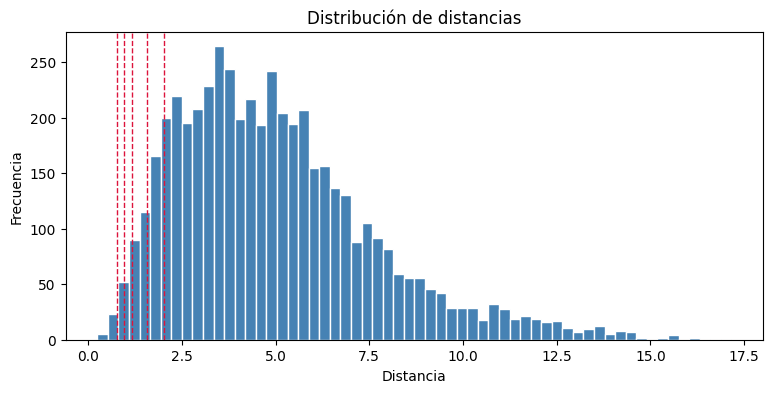

r1 = 0.7660   (percentil 0.5%)
r2 = 0.9477   (percentil 1%)
r3 = 1.1647   (percentil 2%)
r4 = 1.5760   (percentil 5%)
r5 = 2.0211   (percentil 10%)


In [4]:
N = 5000
rng = np.random.default_rng(42)

distances = []
for _ in range(N):
    i, j = rng.choice(n, size=2, replace=False)
    distances.append(euclidean_distance(X[i], X[j]))
distances = np.array(distances)

percentiles = [0.5, 1, 2, 5, 10]
radios = np.percentile(distances, percentiles)

plt.figure(figsize=(9, 4))
plt.hist(distances, bins=60, color="steelblue", edgecolor="white")
for r in radios:
    plt.axvline(r, color="crimson", linestyle="--", linewidth=1)
plt.title("Distribución de distancias")
plt.xlabel("Distancia")
plt.ylabel("Frecuencia")
plt.show()

for k, (p, r) in enumerate(zip(percentiles, radios), start=1):
    print(f"r{k} = {r:.4f}   (percentil {p}%)")

### b) Búsqueda por rango - O(nD)

In [5]:
def range_search(collection, query, r):
    result = []
    for i in range(len(collection)):
        if euclidean_distance(collection[i], query) <= r:
            result.append(i)
    return result

### Precisión = relevantes recuperados / recuperados

In [6]:
def precision(retrieved_labels, query_label):
    if len(retrieved_labels) == 0:
        return float("nan")
    relevant = sum(1 for label in retrieved_labels if label == query_label)
    return relevant / len(retrieved_labels)

### Experimento
La consulta se retira de la colección antes de buscar.

In [7]:
queries = [15, 2166, 4768]
precision_table = {}
size_table = {}

for q in queries:
    collection = np.delete(X, q, axis=0)
    labels = np.delete(y, q)

    precision_table[f"Q{q}"] = []
    size_table[f"Q{q}"] = []
    for r in radios:
        result = range_search(collection, X[q], r)
        precision_table[f"Q{q}"].append(precision(labels[result], y[q]))
        size_table[f"Q{q}"].append(len(result))

row_names = [f"r{k} = {r:.4f}" for k, r in enumerate(radios, start=1)]
print("Precisión (PR)")
pd.DataFrame(precision_table, index=row_names).round(4)

Precisión (PR)


,Q15,Q2166,Q4768
r1 = 0.7660,1.0000,1.0000,0.9722
r2 = 0.9477,1.0000,0.4286,0.9873
r3 = 1.1647,1.0000,0.4231,0.9891
r4 = 1.5760,0.9945,0.3263,0.9565
r5 = 2.0211,0.9891,0.2651,0.8777


In [8]:
print("Objetos recuperados")
pd.DataFrame(size_table, index=row_names)

Objetos recuperados


,Q15,Q2166,Q4768
r1 = 0.7660,43,2,36
r2 = 0.9477,76,7,79
r3 = 1.1647,158,26,183
r4 = 1.5760,362,190,506
r5 = 2.0211,736,747,916
